In [1]:
import os
import pandas as pd

import spacy
import nltk
from dataset_wo_config_files import read_conll_file, make_dict_of_sentences_no_cross
import seaborn as sns
import matplotlib.pyplot as plt


c:\Users\Sergio\miniconda3\envs\mbib\lib\site-packages\tqdm\auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
sp = spacy.load('en_core_web_sm')
spacy_stopwords = sp.Defaults.stop_words
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Sergio\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [3]:
def get_sentences_by_split(dataset_folder, split_name):
    docs_path = os.path.join(dataset_folder + split_name + '/', 'dataset.conll')
    documents, topics = read_conll_file(docs_path)
    sentences_dict = make_dict_of_sentences_no_cross(documents)

    all_sentences = []
    for doc in sentences_dict.values():
        for sentence in doc.values():
            sentence_str = ' '.join([token[2] for token in sentence])
            all_sentences.append(sentence_str)

    return all_sentences

In [4]:
#ECB+:
common_data_folder = "../CDCR/data/"
dataset_name = 'ECBplus-prep'
dataset_folder = f"{common_data_folder}{dataset_name}/output_data/"
split_name = 'train'
ecbplus_sentences_train = get_sentences_by_split(dataset_folder, split_name)

split_name = 'test'
ecbplus_sentences_test = get_sentences_by_split(dataset_folder, split_name)

split_name = 'val'
ecbplus_sentences_val = get_sentences_by_split(dataset_folder, split_name)

ecbplus_sentences = ecbplus_sentences_train + ecbplus_sentences_test + ecbplus_sentences_val


In [5]:
#NewsWCL50:
dataset_name = 'NewsWCL50-prep'
dataset_folder = f"{common_data_folder}{dataset_name}/output_data/"
split_name = 'train'
newswcl50_sentences_train = get_sentences_by_split(dataset_folder, split_name)

split_name = 'test'
newswcl50_sentences_test = get_sentences_by_split(dataset_folder, split_name)

split_name = 'val'
newswcl50_sentences_val = get_sentences_by_split(dataset_folder, split_name)

newswcl50_sentences = newswcl50_sentences_train + newswcl50_sentences_test + newswcl50_sentences_val


In [6]:
# sentences_dict['1/1ecb/1'][2]
# This is going to be key to reproduce CLCOREF

In [7]:
# I need to squeeze the dictionary to create a list of sentences from it. First attempt via 
# Inefficient for loop

In [8]:
# Function to get top tokens
def get_top_tokens(sentences_list, num_tokens=10000):
    # Handle NaN values by converting them to an empty string
    sentences_list = [str(sent) for sent in sentences_list if pd.notna(sent)]
    
    # Join the sentences and tokenize
    tokens = nltk.word_tokenize(" ".join(sentences_list))

    text_without_stopword = [word for word in tokens if word not in spacy_stopwords]

    # Create a frequency distribution of the tokens
    freq_dist = nltk.FreqDist(text_without_stopword)

    # Retrieve the top N most frequent tokens
    top_tokens = freq_dist.most_common(num_tokens)

    # Extract just the tokens (without frequencies)
    top_tokens_only = set([token[0] for token in top_tokens])

    return top_tokens_only


In [9]:
top_10000_ecbplus = get_top_tokens(ecbplus_sentences)
top_10000_newswcl50 = get_top_tokens(newswcl50_sentences)

In [10]:
def jaccard_similarity(set1, set2):
    intersection_size = len(set1.intersection(set2))
    union_size = len(set1.union(set2))
    
    if union_size == 0:
        return 0  # Avoid division by zero
    
    similarity = intersection_size / union_size
    return similarity

In [11]:
jaccard_similarity(top_10000_ecbplus,top_10000_newswcl50)

0.2590011614401858

In [12]:
# Specify the directory containing the CSV files
directory_path = os.path.join(os.path.dirname(os.getcwd()),'MBIB-main','datasets','mbib-aggregated')

# List of CSV files
csv_files = [
    "cognitive-bias.csv",
    "fake-news.csv",
    "gender-bias.csv",
    "hate-speech.csv",
    "linguistic-bias.csv",
    "political-bias.csv",
    "racial-bias.csv",
    "text-level-bias.csv"
]

# Create an empty dictionary to store DataFrames
dataframes_dict = {}

# Load each CSV file into a DataFrame and store in the dictionary
for file_name in csv_files:
    file_path = os.path.join(directory_path, file_name)
    df = pd.read_csv(file_path)
    # Remove file extension to use as the dictionary key
    key = os.path.splitext(file_name)[0]
    dataframes_dict[key] = df

# Now dataframes_dict contains all DataFrames with keys as file names (without extension)


In [13]:
# Create a new dictionary for processed DataFrames using get_top_tokens function
processed_dataframes_dict = {}

# Process each DataFrame and store the result in the new dictionary
for key, df in dataframes_dict.items():
    sentences_list = df['text'].tolist()
    top_tokens = get_top_tokens(sentences_list)
    processed_dataframes_dict[key] = top_tokens

processed_dataframes_dict["ECBplus"] = set(top_10000_ecbplus)
processed_dataframes_dict["NewsWCL50"] = set(top_10000_newswcl50)

# processed_dataframes_dict.pop('fake-news',None)
# processed_dataframes_dict.pop('racial-bias',None)

In [14]:
processed_dataframes_dict.keys()

dict_keys(['cognitive-bias', 'fake-news', 'gender-bias', 'hate-speech', 'linguistic-bias', 'political-bias', 'racial-bias', 'text-level-bias', 'ECBplus', 'NewsWCL50'])

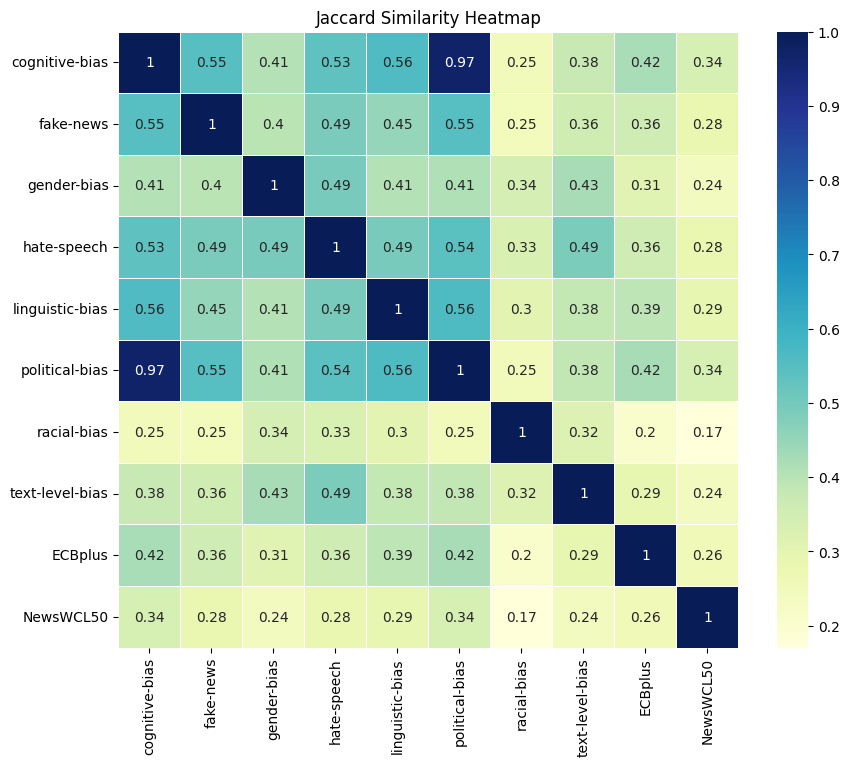

In [15]:

# Calculate Jaccard similarity for all pairs in processed_dataframes_dict
similarity_matrix = pd.DataFrame(index=processed_dataframes_dict.keys(), columns=processed_dataframes_dict.keys())

for key1, set1 in processed_dataframes_dict.items():
    for key2, set2 in processed_dataframes_dict.items():
            similarity_matrix.loc[key1, key2] = jaccard_similarity(set1, set2)

# Convert the dataframe values to numeric
similarity_matrix = similarity_matrix.apply(pd.to_numeric)

# Create a heatmap using seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(similarity_matrix, annot=True, cmap="YlGnBu", linewidths=.5)
plt.title("Jaccard Similarity Heatmap")
plt.show()

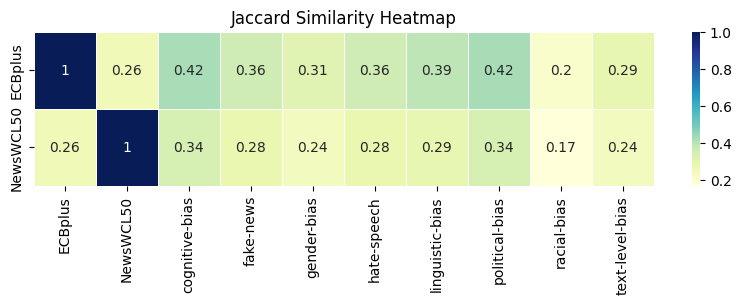

In [16]:
# Extract keys for rows and columns
rows = ['ECBplus', 'NewsWCL50']
columns = ['ECBplus', 'NewsWCL50']
columns.extend([key for key in processed_dataframes_dict if key not in rows])



# Calculate Jaccard similarity for specified pairs
similarity_matrix = pd.DataFrame(index=rows, columns=columns)

for row_key in rows:
    for col_key in columns:
        similarity_matrix.loc[row_key, col_key] = jaccard_similarity(
            processed_dataframes_dict[row_key], processed_dataframes_dict[col_key]
        )

# Convert the dataframe values to numeric
similarity_matrix = similarity_matrix.apply(pd.to_numeric)

# Create a heatmap using seaborn
plt.figure(figsize=(10, 2))
sns.heatmap(similarity_matrix, annot=True, cmap="YlGnBu", linewidths=.5, square=False)
plt.title("Jaccard Similarity Heatmap")
plt.show()

In [17]:
### Check average document size

In [18]:
# Calculate average length for each dataset
for dataset_name, dataset_data in dataframes_dict.items():
    try:
        string_list = dataset_data['text']
        average_length = sum(len(s) for s in string_list) / len(string_list)
        print(f"Average length of strings in {dataset_name}: {average_length}")

    except TypeError as e:
        print(f"Error in {dataset_name}: {e}")

Average length of strings in cognitive-bias: 233.0685998825949
Error in fake-news: object of type 'float' has no len()
Average length of strings in gender-bias: 128.2008380724334
Average length of strings in hate-speech: 270.87579694592534
Average length of strings in linguistic-bias: 283.94485896448947
Error in political-bias: object of type 'float' has no len()
Average length of strings in racial-bias: 96.61248467511238
Average length of strings in text-level-bias: 186.382457307607


In [22]:
dataframes_dict["cognitive-bias"]

pandas.core.frame.DataFrame

In [20]:
dataframes_dict["political-bias"]

,id,text,label,dataset_id
0,066-659367-10,It is clear that Mike Huckabee is definitely a...,0,66
1,066-346205-1,My family has just finished the discussion ab...,0,66
2,066-357786-54,The tragedy which left five police officers de...,0,66
3,066-208937-4,Our four pillar growth strategy focus on serv...,0,66
4,066-509640-49,MICHIGAN Sen Debbie Stabenow D Mich has a 6 po...,0,66
...,...,...,...,...
501683,066-1890265-1,The Oklahoma based Storm Prediction Center say...,1,66
501684,066-929069-6,That stipulation is what worries the two lawma...,1,66
501685,066-2163880-4,On OTRs on the runs the British side undertoo...,1,66
501686,066-1123051-21,Jang Jin Sung who was a prominent propagandist...,1,66


In [19]:
for dataset_name, dataset_data in dataframes_dict.items():
    print(dataset_data.dataset_id.value_counts())

66    474752
72     12450
Name: dataset_id, dtype: int64
72    7254
25    3902
12    2224
Name: dataset_id, dtype: int64
105    14596
107    13017
75     11360
106     1119
Name: dataset_id, dtype: int64
40    328073
92      7271
75      7024
87      6150
Name: dataset_id, dtype: int64
26    339009
35     34570
3      11730
75     10840
49      3498
10      3480
9       1440
38       721
Name: dataset_id, dtype: int64
66    480492
29     17534
49      3662
Name: dataset_id, dtype: int64
75     9335
110     453
Name: dataset_id, dtype: int64
76    8597
19     421
Name: dataset_id, dtype: int64


In [41]:
mixed_political_cognitive= pd.concat([dataframes_dict["political-bias"], dataframes_dict["cognitive-bias"]])
mixed_political_cognitive.drop_duplicates(subset=["text"],inplace=True)
mixed_political_cognitive.drop(["id","dataset_id"],axis=1,inplace=True)
mixed_political_cognitive.columns=["text","label_bias"]

In [36]:
mixed_political_cognitive.label_bias.unique()

array(['0', 'False', '1', 'True', 0, 1], dtype=object)

In [42]:
#Map labels to binary value
mixed_political_cognitive['label_bias'] = mixed_political_cognitive['label_bias'].map({'0': 0, 'False': 0, '1': 1, 'True': 1})
mixed_political_cognitive.dropna(inplace=True)

In [43]:
mixed_political_cognitive.to_excel("dapt_bias_dataset.xlsx",index=False)